# Base de Dados para Modelo de Recomendação - Aventura Teatros

## 1. Introdução

O Portal Aventura atualmente não possui um sistema estruturado de recomendação de espetáculos. Isso faz com que visitantes acessem uma página de um espetáculo sem receber sugestões de outras experiências relevantes, reduzindo a descoberta de conteúdo e a conversão em vendas.

Este notebook tem como objetivo estruturar e preparar a base de dados que alimentará o modelo de **filtragem colaborativa**. Nessa abordagem, as recomendações são geradas com base no padrão de avaliações de usuários com perfis semelhantes, ou seja, se dois usuários avaliaram positivamente espetáculos parecidos no passado, o sistema recomenda ao primeiro o que o segundo também gostou.

## 1.1 Estratégia de Feedback Implícito

A base disponível registra compras e interações transacionais dos usuários com os espetáculos. Como não há uma avaliação explícita confiável informada pelo usuário, a coluna `avaliacao` deixa de ser populada artificialmente e passa a ser derivada de sinais comportamentais reais.

### Sinais utilizados

| Sinal | Origem | Interpretação |
|---|---|---|
| Recorrência usuário-evento | Quantidade de registros para o mesmo par `id_user` + `evento` | Repetição indica maior interesse ou engajamento com o espetáculo |
| Valor do ingresso | `valor_do_ingresso` | Maior disposição de pagamento sugere maior força de preferência |
| Antecedência da compra | Diferença entre `data_da_apresentacao` e `data_da_compra` | Compra antecipada indica planejamento e intenção mais forte |

### Fórmula do score

Os sinais são normalizados em escala relativa e combinados em um `score_implicito` contínuo:

```python
score_implicito = (
    0.60 * score_recorrencia +
    0.25 * score_valor_ingresso +
    0.15 * score_antecedencia
)
```

A recorrência recebe o maior peso por representar o sinal mais diretamente ligado à relação usuário-item. O valor do ingresso entra como compromisso financeiro, e a antecedência atua como sinal complementar de intenção.

Após a consolidação por par usuário-item, o score contínuo é convertido em ratings ordinais de 1 a 5 por quintis. Dessa forma, o pipeline continua compatível com filtragem colaborativa baseada em ratings, mas os valores passam a refletir comportamento real observado na base.

### Produção (enriquecimento por cruzamento de bases)

A coluna `tipo_producao` foi preenchida a partir do cruzamento entre a base principal e uma planilha auxiliar contendo informações dos espetáculos, como produção externa, companhia ou corporativa. O cruzamento utiliza o nome do espetáculo como chave e aplica padronização textual para aumentar a taxa de correspondência.

```python
import pandas as pd

df1 = pd.read_csv("base_tratada.csv", sep=";", encoding="latin1")
df2 = pd.read_csv("base_espetaculos.csv", sep=";", encoding="latin1")

df1.columns = df1.columns.str.strip().str.lower()
df2.columns = df2.columns.str.strip().str.lower()

df1["nome_evento"] = df1["nome_evento"].str.strip().str.lower()
df2["nome_espetaculo"] = df2["nome_espetaculo"].str.strip().str.lower()

df_final = df1.merge(
    df2,
    how="left",
    left_on="nome_evento",
    right_on="nome_espetaculo"
)

df_final["tipo_producao"] = df_final["producao"]
df_final = df_final.drop(columns=["nome_espetaculo", "producao"])
df_final.to_csv("base_final.csv", index=False)
```


## 2. Carregamento do Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Estilo de visualização
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)

# Carregamento
df = pd.read_csv('../dataset/recomendacao.csv')
df = df.rename(columns={'evento': 'nome_evento'})
if 'tipo_producao' not in df.columns:
    df['tipo_producao'] = 'Nao informado'

# Feedback implicito derivado de comportamento real
valor = pd.to_numeric(df['valor_do_ingresso'], errors='coerce').fillna(0).clip(lower=0)
compra = pd.to_datetime(df['data_da_compra'], errors='coerce', format='mixed')
apresentacao = pd.to_datetime(df['data_da_apresentacao'], errors='coerce', format='mixed')
antecedencia = (apresentacao - compra).dt.total_seconds().div(86400).clip(lower=0, upper=365).fillna(0)
interacoes = df.groupby(['id_user', 'nome_evento'])['nome_evento'].transform('size')

score_recorrencia = np.log1p(interacoes) / np.log1p(interacoes.max())
score_valor = valor.rank(pct=True, method='average')
score_antecedencia = antecedencia.rank(pct=True, method='average')

df['interacoes_user_item'] = interacoes.astype(int)
df['antecedencia_dias'] = antecedencia.round(2)
df['score_implicito'] = (
    0.60 * score_recorrencia +
    0.25 * score_valor +
    0.15 * score_antecedencia
).round(6)

# Rating inicial por linha, usado apenas para EDA. O rating final do modelo e recalculado apos a agregacao user-item.
df['avaliacao'] = pd.qcut(
    df['score_implicito'].rank(method='first'),
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

print('Dataset carregado com sucesso!')
print(f'   Registros: {len(df):,}')
print(f'   Colunas:   {df.shape[1]}')
print('Distribuicao inicial do rating implicito:')
print(df['avaliacao'].value_counts().sort_index().to_string())
df.head()


Dataset carregado com sucesso!
   Registros: 343,758
   Colunas:   13
Distribuicao inicial do rating implicito:
avaliacao
1    68752
2    68751
3    68752
4    68751
5    68752


,id_user,nome_evento,teatro,data_da_apresentacao,data_da_compra,setor,valor_do_ingresso,categoria,interacoes_user_item,antecedencia_dias,score_implicito,avaliacao,tipo_producao
0,1,UM MALLANDRO NA QUARENTENA COM SERGIO MALLANDRO,TEATRO RIACHUELO RJ,6/26/21 20:00,5/20/21 5:03,PLATEIA VIP - 02 PESSOAS,120,Show Stand-Up,2,37.62,0.423159,4,Nao informado
1,1,UM MALLANDRO NA QUARENTENA COM SERGIO MALLANDRO,TEATRO RIACHUELO RJ,6/26/21 20:00,5/20/21 5:03,PLATEIA VIP - 02 PESSOAS,120,Show Stand-Up,2,37.62,0.423159,4,Nao informado
2,2,DOMINGUINHOS - ISSO AQUI TÁ BOM DEMAIS,TEATRO RIACHUELO RJ,6/9/23 20:00,6/9/23 10:04,BALCÃO,50,Show Musical,2,0.41,0.246115,1,Nao informado
3,2,DOMINGUINHOS - ISSO AQUI TÁ BOM DEMAIS,TEATRO RIACHUELO RJ,6/9/23 20:00,6/9/23 10:04,BALCÃO,50,Show Musical,2,0.41,0.246115,1,Nao informado
4,3,A NOVIÇA REBELDE,TEATRO RIACHUELO RJ,5/11/24 19:00,5/10/24 20:33,PLATEIA,225,Espetáculo Musical,1,0.94,0.321727,3,Nao informado


## 3. Descrição do Dataset

In [2]:
print('=== Informações Gerais do Dataset ===') 
print(f'Registros totais       : {len(df):>10,}')
print(f'Usuários únicos        : {df["id_user"].nunique():>10,}')
print(f'Espetáculos únicos     : {df["nome_evento"].nunique():>10,}')
print(f'Teatros únicos         : {df["teatro"].nunique():>10,}')
print(f'Categorias únicas      : {df["categoria"].nunique():>10,}')
print('\nColunas disponíveis:')
for col in df.columns:
    print(f'  - {col} ({df[col].dtype})')
print()
print('=== Tipos e Nulos ===')    
print(df.dtypes)
print()
print('Valores nulos por coluna:')
print(df.isnull().sum())


=== Informações Gerais do Dataset ===
Registros totais       :    343,758
Usuários únicos        :     68,564
Espetáculos únicos     :        571
Teatros únicos         :          4
Categorias únicas      :          8

Colunas disponíveis:
  - id_user (int64)
  - nome_evento (object)
  - teatro (object)
  - data_da_apresentacao (object)
  - data_da_compra (object)
  - setor (object)
  - valor_do_ingresso (object)
  - categoria (object)
  - interacoes_user_item (int64)
  - antecedencia_dias (float64)
  - score_implicito (float64)
  - avaliacao (int64)
  - tipo_producao (object)

=== Tipos e Nulos ===
id_user                   int64
nome_evento              object
teatro                   object
data_da_apresentacao     object
data_da_compra           object
setor                    object
valor_do_ingresso        object
categoria                object
interacoes_user_item      int64
antecedencia_dias       float64
score_implicito         float64
avaliacao                 int64
tipo_prod

In [3]:
print('Estatísticas descritivas do feedback implícito:')
df[['score_implicito', 'avaliacao', 'interacoes_user_item', 'antecedencia_dias']].describe().round(2)

Estatísticas descritivas do feedback implícito:


,score_implicito,avaliacao,interacoes_user_item,antecedencia_dias
count,343758.00,343758.00,343758.00,343758.00
mean,0.38,3.00,270.18,21.23
std,0.14,1.41,834.72,31.64
min,0.08,1.00,1.00,0.00
25%,0.28,2.00,2.00,2.17
50%,0.35,3.00,3.00,10.32
75%,0.44,4.00,15.00,29.19
max,0.99,5.00,5326.00,365.00


In [4]:
print('Interações por usuário:')
user_counts = df.groupby('id_user').size()
display(user_counts.describe().rename('interações').to_frame())

print('\nInterações por espetáculo:')
item_counts = df.groupby('nome_evento').size()
display(item_counts.describe().rename('interações').to_frame())

Interações por usuário:


,interações
count,68564.000000
mean,5.013681
std,303.798229
min,1.000000
25%,2.000000
50%,2.000000
75%,4.000000
max,79505.000000



Interações por espetáculo:


,interações
count,571.000000
mean,602.028021
std,1917.011590
min,1.000000
25%,63.500000
50%,154.000000
75%,401.000000
max,32475.000000


## 4. Análise do Balanceamento do Dataset

Antes de aplicar qualquer transformação, analisamos a distribuição bruta dos dados para identificar os principais problemas de balanceamento

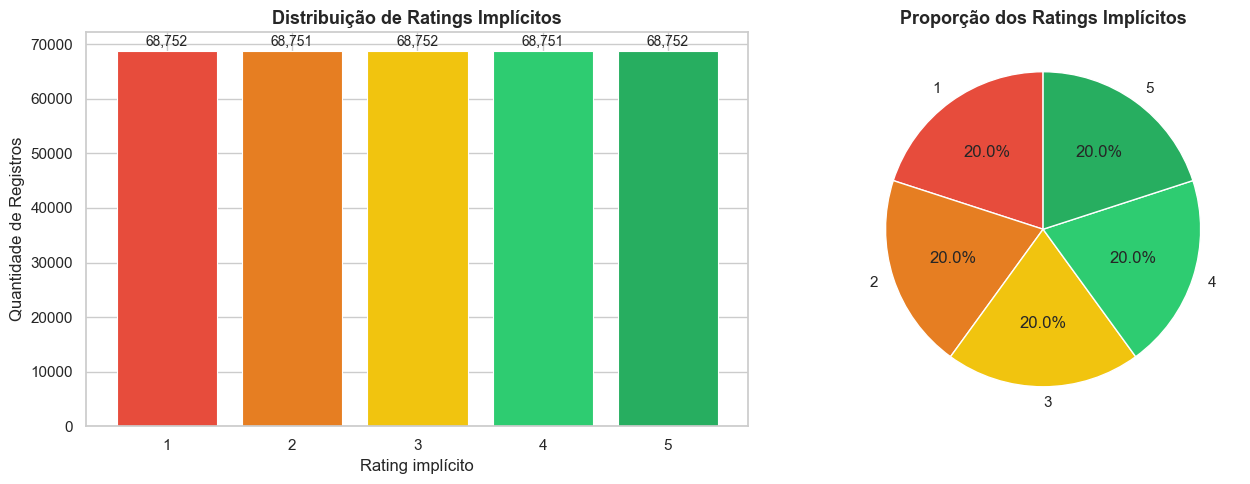

Distribuição inicial calculada por quintis do score implícito.


In [5]:
# Distribuição dos ratings implícitos
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

rating_counts = df['avaliacao'].value_counts().sort_index()

# Barras
bars = axes[0].bar(rating_counts.index, rating_counts.values,
                   color=['#e74c3c','#e67e22','#f1c40f','#2ecc71','#27ae60'],
                   edgecolor='white', linewidth=0.8)
axes[0].set_title('Distribuição de Ratings Implícitos', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Rating implícito')
axes[0].set_ylabel('Quantidade de Registros')
for bar, val in zip(bars, rating_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 500,
                 f'{val:,}', ha='center', va='bottom', fontsize=10)

# Pizza
pct = rating_counts / rating_counts.sum() * 100
axes[1].pie(pct, labels=[f'{i}' for i in rating_counts.index],
            autopct='%1.1f%%', colors=['#e74c3c','#e67e22','#f1c40f','#2ecc71','#27ae60'],
            startangle=90)
axes[1].set_title('Proporção dos Ratings Implícitos', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()
print('Distribuição inicial calculada por quintis do score implícito.')

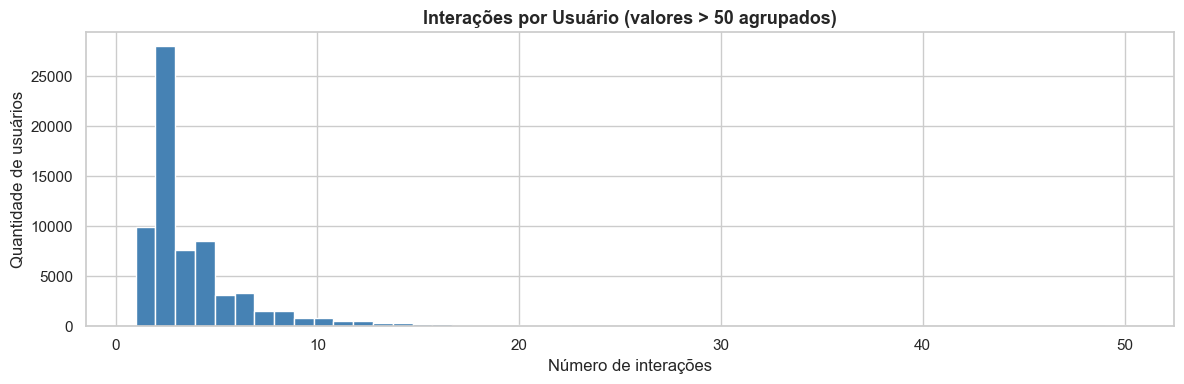

 Usuário outlier: ID 68564 com 79,505 interações
   Mediana de interações por usuário: 2
   Usuários com apenas 1 interação: 9,883


In [6]:
# Distribuição de interações por usuário
fig, ax = plt.subplots(figsize=(12, 4))
clipped = user_counts.clip(upper=50) # Limitar para visualização
ax.hist(clipped, bins=50, color='steelblue', edgecolor='white')
ax.set_title('Interações por Usuário (valores > 50 agrupados)', fontsize=13, fontweight='bold')
ax.set_xlabel('Número de interações')
ax.set_ylabel('Quantidade de usuários')
plt.tight_layout()
plt.show()

outlier_user = user_counts.idxmax()
print(f' Usuário outlier: ID {outlier_user} com {user_counts.max():,} interações')
print(f'   Mediana de interações por usuário: {user_counts.median():.0f}')
print(f'   Usuários com apenas 1 interação: {(user_counts == 1).sum():,}')

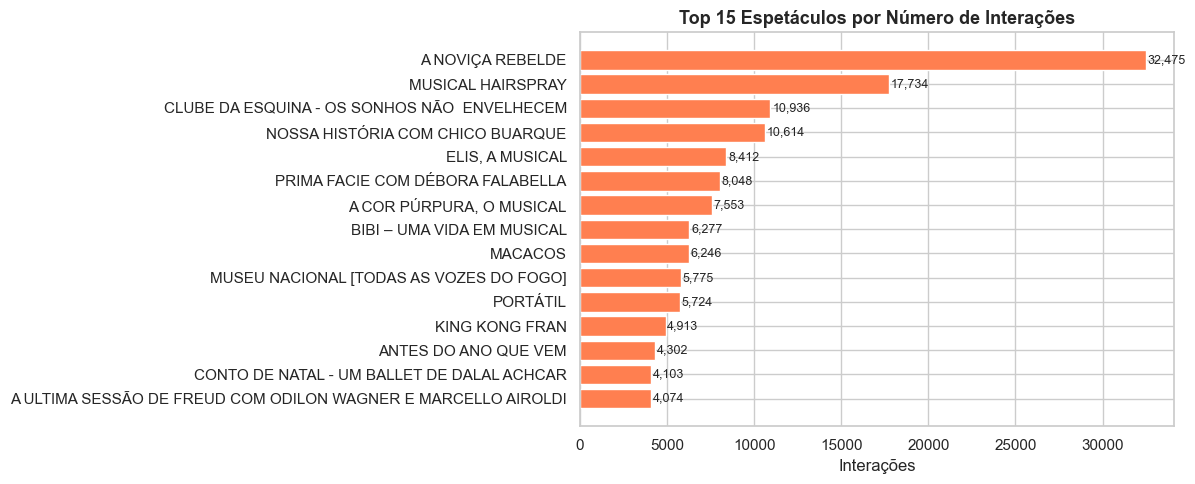

In [7]:
# Top 15 espetáculos mais avaliados
top_items = item_counts.sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.barh(top_items.index[::-1], top_items.values[::-1], color='coral', edgecolor='white')
ax.set_title('Top 15 Espetáculos por Número de Interações', fontsize=13, fontweight='bold')
ax.set_xlabel('Interações')
for bar, val in zip(bars, top_items.values[::-1]):
    ax.text(bar.get_width() + 100, bar.get_y() + bar.get_height()/2,
            f'{val:,}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

### 4.1 Balanceamento - Passo a Passo

Aplicaremos as seguintes etapas:

| Passo | Ação | Justificativa |
|---|---|---|
| 1 | Agregar duplicatas por par user-item | Consolida múltiplas compras/interações do mesmo usuário no mesmo espetáculo |
| 2 | Remover usuário outlier extremo | Usuários com volume anormal distorcem os padrões colaborativos |
| 3 | Filtrar cold start de usuários (< 3 interações) | Usuários raros não geram histórico suficiente para recomendação |
| 4 | Filtrar cold start de itens (< 10 interações) | Itens raros não possuem interações suficientes para aprendizado |
| 5 | Converter score implícito em rating ordinal | Gera ratings 1-5 a partir de comportamento real no nível user-item |
| 6 | Reavaliar balanceamento dos ratings | Aplica undersampling apenas se alguma classe ultrapassar 2x a menor classe |



In [8]:
df = df.copy()

df_agg = (
    df.groupby(['id_user', 'nome_evento'], as_index=False)
      .agg(score_implicito=('score_implicito', 'mean'),
           interacoes_user_item=('interacoes_user_item', 'max'),
           antecedencia_dias=('antecedencia_dias', 'mean'),
           valor_medio=('valor_do_ingresso', lambda s: pd.to_numeric(s, errors='coerce').fillna(0).mean()),
           categoria=('categoria', 'first'),
           tipo_producao=('tipo_producao', 'first'),
           teatro=('teatro', 'first'))
)

print(f'Registros antes da agregação : {len(df):>10,}')
print(f'Registros após agregação      : {len(df_agg):>10,}')
print(f'Redução                       : {len(df) - len(df_agg):>10,} registros')


Registros antes da agregação :    343,758
Registros após agregação      :    112,347
Redução                       :    231,411 registros


In [9]:
# Remover usuário outlier extremo
user_freq = df_agg.groupby('id_user').size()

# Remover usuários com mais de 500 interações (outlier extremo)
MAX_USER_INTERACTIONS = 500
valid_users = user_freq[user_freq <= MAX_USER_INTERACTIONS].index

df_agg = df_agg[df_agg['id_user'].isin(valid_users)]

removed = (~df_agg['id_user'].isin(valid_users)).sum()
print(f'Usuários outlier removidos    : {(user_freq > MAX_USER_INTERACTIONS).sum()}')
print(f'Registros após remoção outlier: {len(df_agg):>10,}')



Usuários outlier removidos    : 1
Registros após remoção outlier:    111,790


In [10]:
# Filtrar cold start de usuários (mínimo 3 interações) 
MIN_USER_INTERACTIONS = 3

user_freq2 = df_agg.groupby('id_user').size()
valid_users2 = user_freq2[user_freq2 >= MIN_USER_INTERACTIONS].index
df_agg = df_agg[df_agg['id_user'].isin(valid_users2)]

print(f'Usuários cold-start removidos : {(user_freq2 < MIN_USER_INTERACTIONS).sum():>10,}')
print(f'Registros após filtro usuário : {len(df_agg):>10,}')

Usuários cold-start removidos :     59,913
Registros após filtro usuário :     41,271


In [11]:
# Filtrar cold start de itens (mínimo 10 interações)
MIN_ITEM_INTERACTIONS = 10

item_freq = df_agg.groupby('nome_evento').size()
valid_items = item_freq[item_freq >= MIN_ITEM_INTERACTIONS].index
df_agg = df_agg[df_agg['nome_evento'].isin(valid_items)]

print(f'Itens cold-start removidos    : {(item_freq < MIN_ITEM_INTERACTIONS).sum():>10,}')
print(f'Registros após filtro item    : {len(df_agg):>10,}')
print(f'Espetáculos restantes         : {df_agg["nome_evento"].nunique():>10,}')

Itens cold-start removidos    :         98
Registros após filtro item    :     40,848
Espetáculos restantes         :        343


In [12]:
# Converter score implicito agregado em rating ordinal e reavaliar balanceamento
# O rating e calculado apos os filtros para representar a distribuicao real usada pelo modelo.

df_agg['avaliacao'] = pd.qcut(
    df_agg['score_implicito'].rank(method='first'),
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rating_dist = df_agg['avaliacao'].value_counts().sort_index()
min_class = rating_dist.min()
target_size = min(min_class * 2, rating_dist.max())  # limite maximo: 2x a menor classe

print('Distribuição antes do balanceamento:')
print(rating_dist.to_string())
print(f'\nLimite por classe: {target_size:,}')

balanced_parts = []
for rating_val, group in df_agg.groupby('avaliacao'):
    if len(group) > target_size:
        group = group.sample(n=target_size, random_state=42)
    balanced_parts.append(group)

df_balanced = pd.concat(balanced_parts).sample(frac=1, random_state=42).reset_index(drop=True)

print('\nDistribuição APÓS balanceamento:')
print(df_balanced['avaliacao'].value_counts().sort_index().to_string())


Distribuição antes do balanceamento:
avaliacao
1    8170
2    8169
3    8170
4    8169
5    8170

Limite por classe: 8,170

Distribuição APÓS balanceamento:
avaliacao
1    8170
2    8169
3    8170
4    8169
5    8170


In [13]:
# criar IDs numéricos para user e item
user_map = {u: i for i, u in enumerate(df_balanced['id_user'].unique())}
item_map = {e: i for i, e in enumerate(df_balanced['nome_evento'].unique())}

df_balanced['user_id'] = df_balanced['id_user'].map(user_map)
df_balanced['item_id'] = df_balanced['nome_evento'].map(item_map)
df_balanced['rating'] = df_balanced['avaliacao'].astype(float)

print(f'Usuários únicos no dataset final : {df_balanced["user_id"].nunique():>8,}')
print(f'Espetáculos únicos no dataset    : {df_balanced["item_id"].nunique():>8,}')
print(f'Registros totais                  : {len(df_balanced):>8,}')
df_balanced[['user_id','item_id','rating','score_implicito','nome_evento','categoria','tipo_producao']].head(10)


Usuários únicos no dataset final :    8,648
Espetáculos únicos no dataset    :      343
Registros totais                  :   40,848


,user_id,item_id,rating,score_implicito,nome_evento,categoria,tipo_producao
0,0,0,4.0,0.332675,HOMEM COM H,Espetáculo Musical,Nao informado
1,1,1,3.0,0.318823,ORQUESTRA PETROBRAS SINFÔNICA – A MAGIA DA ORQ...,Concertos Instrumentais,Nao informado
2,2,2,3.0,0.311547,STAND UP BRUNA LOUISE - BURN OUT,Show Stand-Up,Nao informado
3,3,3,2.0,0.250438,MUSICAL HAIRSPRAY,Espetáculo Musical,Nao informado
4,4,4,2.0,0.247016,A NOVIÇA REBELDE,Espetáculo Musical,Nao informado
5,5,5,2.0,0.276252,AFONSO PADILHA EM E AGORA ?,Show Stand-Up,Nao informado
6,6,6,1.0,0.216071,BIBI – UMA VIDA EM MUSICAL,Espetáculo Musical,Nao informado
7,7,7,1.0,0.218290,"EVOÉ, O MUSICAL",Espetáculo Musical,Nao informado
8,8,8,2.0,0.273386,CONTO DE NATAL - UM BALLET DE DALAL ACHCAR,Espetáculo de Dança,Nao informado
9,9,9,3.0,0.306084,VIVA O POVO BRASILEIRO [DE NAÊ À DAFÉ],Show Musical,Nao informado


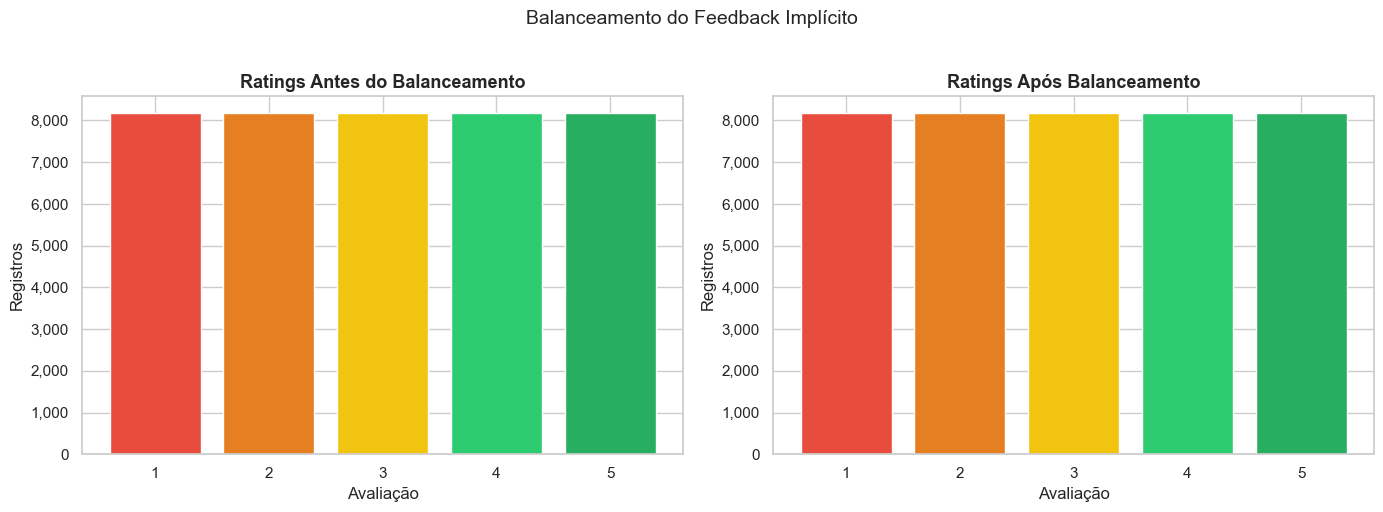

In [14]:
# Visualização comparativa ANTES x DEPOIS 
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = ['#e74c3c','#e67e22','#f1c40f','#2ecc71','#27ae60']

# ANTES
before = df_agg['avaliacao'].value_counts().sort_index()
axes[0].bar(before.index, before.values, color=colors, edgecolor='white')
axes[0].set_title('Ratings Antes do Balanceamento', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Avaliação'); axes[0].set_ylabel('Registros')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

# DEPOIS
after = df_balanced['avaliacao'].value_counts().sort_index()
axes[1].bar(after.index, after.values, color=colors, edgecolor='white')
axes[1].set_title('Ratings Após Balanceamento', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Avaliação'); axes[1].set_ylabel('Registros')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

plt.suptitle('Balanceamento do Feedback Implícito', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


Matriz user-item: 8,648 x 343
Interações preenchidas: 40,848
Esparsidade da matriz: 98.6229%


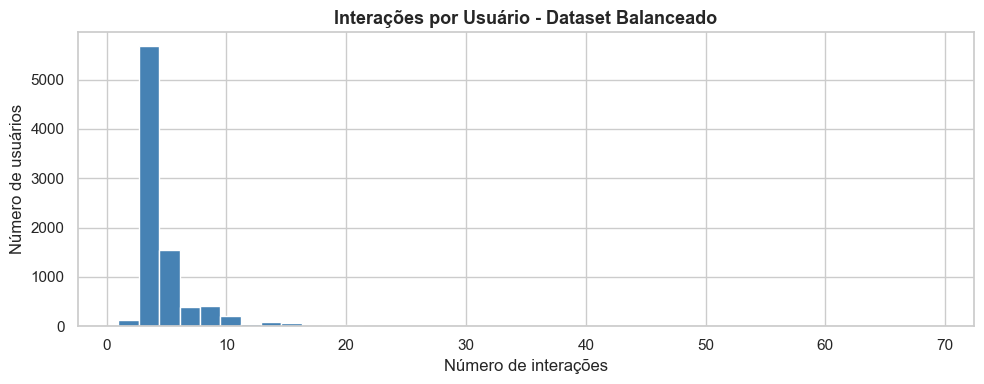

In [15]:
# Esparsidade da matriz user-item
n_users = df_balanced['user_id'].nunique()
n_items = df_balanced['item_id'].nunique()
n_interactions = len(df_balanced)
sparsity = 1 - (n_interactions / (n_users * n_items))

print(f'Matriz user-item: {n_users:,} x {n_items:,}')
print(f'Interações preenchidas: {n_interactions:,}')
print(f'Esparsidade da matriz: {sparsity:.4%}')

# Distribuição final de interações por usuário
fig, ax = plt.subplots(figsize=(10, 4))
df_balanced.groupby('user_id').size().hist(bins=40, ax=ax, color='steelblue', edgecolor='white')
ax.set_title('Interações por Usuário - Dataset Balanceado', fontsize=13, fontweight='bold')
ax.set_xlabel('Número de interações')
ax.set_ylabel('Número de usuários')
plt.tight_layout()
plt.show()


In [16]:
# Salvar dataset final
# Arquivo principal para o modelo (Spotlight)
df_final = df_balanced[['user_id', 'item_id', 'rating', 'score_implicito']]
df_final.to_csv('../dataset/recomendacao_balanceado.csv', index=False)

# Arquivo auxiliar com metadados dos itens (útil para exibir nomes nas recomendações)
item_meta = (df_balanced[['item_id','nome_evento','categoria','tipo_producao']]
             .drop_duplicates('item_id')
             .sort_values('item_id'))
item_meta.to_csv('../dataset/itens_metadata.csv', index=False)

print('Arquivos salvos com sucesso!')
print(f'   recomendacao_balanceado.csv  -> {len(df_final):,} registros')
print(f'   itens_metadata.csv           -> {len(item_meta):,} espetáculos')
df_final.head()


Arquivos salvos com sucesso!
   recomendacao_balanceado.csv  -> 40,848 registros
   itens_metadata.csv           -> 343 espetáculos


,user_id,item_id,rating,score_implicito
0,0,0,4.0,0.332675
1,1,1,3.0,0.318823
2,2,2,3.0,0.311547
3,3,3,2.0,0.250438
4,4,4,2.0,0.247016


## 5. Conclusão

### Descobertas Principais

A análise exploratória revelou um dataset rico em sinais transacionais, mas sem avaliações explícitas confiáveis dos usuários. Por isso, a coluna `avaliacao` foi reconstruída como feedback implícito a partir de comportamento real observado na base.

1. **Substituição dos ratings sintéticos**: A geração probabilística de avaliações foi removida. O rating passou a ser derivado de recorrência no par usuário-evento, valor do ingresso e antecedência da compra.

2. **Duplicatas por (usuário, evento)**: Múltiplos registros do mesmo par usuário-evento (máximo: 5.326 para o mesmo par) foram agregados em uma única interação, preservando o score implícito médio e a maior recorrência observada.

3. **Outlier crítico**: O usuário de ID `68564` concentrava 79.505 registros, cerca de 23% do dataset inteiro. Esse volume é incompatível com comportamento humano normal e foi removido antes do treinamento.

4. **Usuários e itens cold-start**: Usuários com menos de 3 interações e itens com menos de 10 interações foram removidos para manter uma matriz colaborativa com histórico mínimo.

5. **Balanceamento revisado**: O balanceamento passou a ser avaliado depois da agregação user-item e da criação dos ratings implícitos. A distribuição final ficou praticamente uniforme, sem perda adicional de registros por undersampling.

### Dataset Final

| Métrica | Valor |
|---|---|
| Total de registros (bruto) | 343.758 |
| Usuários únicos (bruto) | 68.564 |
| Eventos únicos (bruto) | 571 |
| Registros após agregação e filtros | 40.848 |
| Usuários no dataset final | 8.648 |
| Eventos no dataset final | 343 |

### Próximos Passos

1. **Divisão treino/teste**: Separar os dados em splits estratificados por usuário para avaliação justa do modelo;
2. **Implementação do modelo**: Experimentar algoritmos de filtragem colaborativa compatíveis com feedback implícito e ratings ordinais, como SVD, NMF, KNN ou LightFM;
3. **Avaliação de métricas**: Medir RMSE, MAE e métricas de ranking como Precision@K e Recall@K;
4. **Validação com o grupo**: Revisar os pesos do score implícito com base no entendimento de negócio;
5. **Integração com o Portal Aventura**: Expor as recomendações via API REST para consumo pelo front-end do portal.
